# HANDS-ON PROJECT: CUSTOMER SEGMENTATION USING K-MEANS

**Course:** Data Science / Applied Machine Learning for Economics and Business  
**Level:** Beginner–Intermediate  
**Format:** Jupyter Notebook (Google Colab or JupyterLab)  
**Suggested duration:** 2–3 practical class sessions, plus time to complete the report  
**Dataset:** [Mall Customer Segmentation Data – Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python)

## Business scenario

You are a data analyst working for a shopping mall. The marketing team wants to identify different types of customers to design more relevant communication and customer-engagement programs, rather than sending the same message to everyone.

**Main question:** Can we segment customers into groups with similar characteristics based on annual income and spending score? Which marketing strategies should the business test for the resulting segments?

> **Important:** This is an *educational dataset*, not sufficient real-world sales data to establish profitability or campaign effectiveness. Spending Score is a behavioral score, **not a monetary spending amount**.

## Learning objectives

By the end of this project, students should be able to:

1. Load, inspect, and summarize a customer dataset using `pandas`.
2. Select suitable features and explain why feature scaling matters.
3. Apply K-means clustering with `scikit-learn`.
4. Compare candidate values of `k` using the **Elbow Method** and **Silhouette Score**.
5. Visualize and profile customer segments, then propose business actions.
6. Assess how the results change when the inputs or scaling choices change.

**Libraries:** `numpy`, `pandas`, `matplotlib`, `seaborn`, and `scikit-learn`; `kagglehub` is optional for downloading data automatically.

## Theory review

K-means partitions `n` observations into `k` clusters, aiming to minimize the within-cluster sum of squared Euclidean distances:

$$
\min_{C_1,\ldots,C_k,\mu_1,\ldots,\mu_k}
\sum_{j=1}^{k}\sum_{x_i\in C_j}\lVert x_i-\mu_j\rVert_2^2.
$$

- **Centroid:** the mean position of the observations in a cluster.
- **Inertia (WCSS):** the sum of squared distances from observations to their assigned centroids. It typically decreases as `k` increases, so it **should not be the only criterion** used to choose `k`.
- **Silhouette Score:** measures within-cluster cohesion and between-cluster separation. Its values are generally in `[-1, 1]`; higher is usually better, but business interpretability also matters.
- **K-means is unsupervised learning:** cluster labels such as `0, 1, 2, ...` are arbitrary identifiers, not rankings, and may change between runs.

**Important:** `CustomerID` is an identifier, not a clustering feature. `Gender` and `Age` can help describe the segments after clustering. To make the core model easy to visualize, use only `Annual Income (k$)` and `Spending Score (1-100)` as clustering features.

## Part 0. Environment setup and dataset access

**Data source:** Vijay Choudhary, *Mall Customer Segmentation Data*, Kaggle.

1. Open the [Kaggle dataset page](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python).
2. Download `Mall_Customers.csv` and place it in the same folder as this notebook, or in a `data/` folder.
3. In Kaggle Notebooks, the dataset is commonly available at `/kaggle/input/customer-segmentation-tutorial-in-python/Mall_Customers.csv` after you add it as an input.
4. If no local file is found, the notebook attempts a download using `kagglehub` (if installed and internet access is available). Depending on the environment, Kaggle authentication may be required.

Install the libraries if necessary:

```python
%pip install -q pandas numpy matplotlib seaborn scikit-learn kagglehub
```

You normally only need to install them once per environment.

In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn kagglehub

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
RANDOM_STATE = 42

In [3]:
# Look for a manually downloaded file before trying kagglehub.
possible_paths = [
    Path("Mall_Customers.csv"),
    Path("data/Mall_Customers.csv"),
    Path("/kaggle/input/customer-segmentation-tutorial-in-python/Mall_Customers.csv"),
]
data_path = next((p for p in possible_paths if p.is_file()), None)

if data_path is None:
    try:
        import kagglehub
        folder = Path(kagglehub.dataset_download(
            "vjchoudhary7/customer-segmentation-tutorial-in-python"
        ))
        matches = list(folder.rglob("Mall_Customers.csv"))
        data_path = matches[0] if matches else None
    except Exception as exc:
        print("Automatic download failed:", exc)

if data_path is None:
    raise FileNotFoundError(
        "Download Mall_Customers.csv from Kaggle and place it beside the notebook or inside data/."
    )

df = pd.read_csv(data_path)
print("Data loaded from:", data_path)
print("Dataset shape:", df.shape)
display(df)

Data loaded from: C:\Users\Ta Van Toan\.cache\kagglehub\datasets\vjchoudhary7\customer-segmentation-tutorial-in-python\versions\1\Mall_Customers.csv
Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


### Data dictionary

| Column | Description | How it is used |
|---|---|---|
| `CustomerID` | Customer identifier | Exclude from K-means |
| `Gender` | Gender recorded in the dataset | Descriptive profiling after clustering |
| `Age` | Customer age (years) | Profiling and extended experiment |
| `Annual Income (k$)` | Annual income in thousands of US dollars | Main clustering feature |
| `Spending Score (1-100)` | Behavioral spending score, from 1 to 100 | Main clustering feature; **not revenue** |

**Initial check:** The Kaggle dataset is described as containing **200 rows and 5 columns**. If your file differs, verify that you loaded the intended CSV.

In [4]:
print("Columns:", df.columns.tolist())
print("Rows and columns:", df.shape)
print("Data types:")
df.info()
print("\nDescriptive statistics:")
display(df.describe(include="all"))

Columns: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']
Rows and columns: (200, 5)
Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Descriptive statistics:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200,200.000000,200.000000,200.000000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500000,NaN,38.850000,60.560000,50.200000
std,57.879185,NaN,13.969007,26.264721,25.823522
min,1.000000,NaN,18.000000,15.000000,1.000000
25%,50.750000,NaN,28.750000,41.500000,34.750000
50%,100.500000,NaN,36.000000,61.500000,50.000000
75%,150.250000,NaN,49.000000,78.000000,73.000000


## Part 1. Data quality checks (15 points)

**Task 1.1.** Count missing values in each column and completely duplicated rows.

**Task 1.2.** Look for invalid values, such as negative ages, negative incomes, or spending scores outside `[1, 100]`.

**Task 1.3.** If you find errors, explain how you would handle them. Do not remove a record simply because it is unusual without a sound reason.

*Hints:* `.isna().sum()`, `.duplicated().sum()`, `.between()`, `.describe()`.

In [5]:
# TODO 1: Check missing values and duplicate records.
print(df.isna().sum())
print(df.duplicated().sum())

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
0


In [6]:
# TODO 2: Check for invalid values in Age, Annual Income (k$),
# and Spending Score (1-100).
# TODO 2: Check for invalid values in Age, Annual Income (k$),
# and Spending Score (1-100).
negative_age = (df['Age'] < 0).sum()
print(negative_age)

negative_income = (df['Annual Income (k$)'] < 0).sum()
print(negative_income)

outside_spending = ((df['Spending Score (1-100)'] < 1) |
                   (df['Spending Score (1-100)'] > 100)).sum()
print(outside_spending)

0
0
0


**Discussion questions:** (a) Should `CustomerID` be included when calculating distances between customers? (b) Is replacing a missing income with zero appropriate? (c) Why should outliers not automatically be removed using a rigid rule?

**Your answers:**

- (a) NO
- (b) NO
- (c) 

## Part 2. Exploratory Data Analysis (EDA) (15 points)

**Task 2.1.** Plot histograms of `Age`, `Annual Income (k$)`, and `Spending Score (1-100)`. Describe their distributions.

**Task 2.2.** Draw a scatter plot with annual income on the x-axis and spending score on the y-axis.

**Task 2.3.** Based on the plot, hypothesize how many customer groups might exist. This is only an initial guess, not a K-means result.

*Hints:* `sns.histplot`, `sns.scatterplot`, `plt.subplots`.

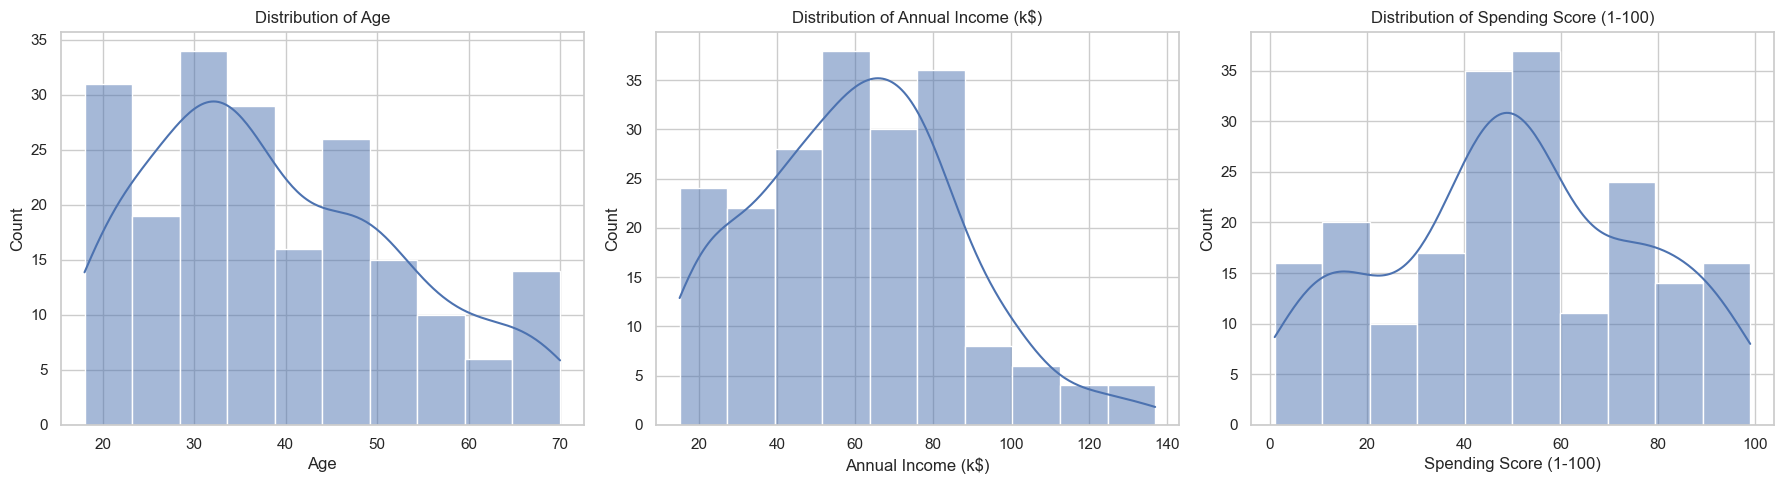

In [23]:
# TODO 3: Create three histograms in a single row.
eda_features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
# Write your code here.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, eda_features):
    sns.histplot(df[col], bins=10, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")
plt.tight_layout()
plt.show()


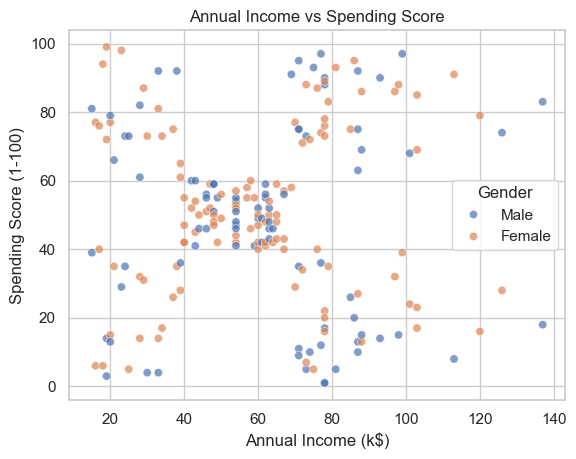

In [8]:
# TODO 4: Plot annual income against spending score.
# x-axis: Annual Income (k$); y-axis: Spending Score (1-100).
# TODO 4: Plot annual income against spending score.
# x-axis: Annual Income (k$); y-axis: Spending Score (1-100).

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue='Gender',
    alpha=0.7
)

plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()

**EDA interpretation:** Describe at least **two observations** from your charts. Explain high and low values using the original units, and do not treat a spending score as revenue.

## Part 3. Feature selection and scaling (10 points)

### Syntax example

```python
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
```

`StandardScaler` transforms each feature according to:

$$ z = \frac{x - \bar{x}}{s}. $$

**Task 3.1.** Select only `Annual Income (k$)` and `Spending Score (1-100)` as features. Exclude `CustomerID`.

**Task 3.2.** Use `StandardScaler` to create `X_scaled`.

**Task 3.3.** Check the means and standard deviations (using NumPy's convention) of the scaled features.

In [25]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]
# TODO 5: Create X from df, then fit scaler and create X_scaled.
X = df[features]
scaler = StandardScaler()
print(scaler)
X_scaled =scaler.fit_transform(X)
print(scaler)
display(X_scaled)
print(np.mean(X_scaled,axis=0))
print(np.std(X_scaled,axis=0))

StandardScaler()
StandardScaler()


array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992],
       [-1.66266033,  1.00159627],
       [-1.62449091, -1.71591298],
       [-1.62449091,  1.70038436],
       [-1.58632148, -1.83237767],
       [-1.58632148,  0.84631002],
       [-1.58632148, -1.4053405 ],
       [-1.58632148,  1.89449216],
       [-1.54815205, -1.36651894],
       [-1.54815205,  1.04041783],
       [-1.54815205, -1.44416206],
       [-1.54815205,  1.11806095],
       [-1.50998262, -0.59008772],
       [-1.50998262,  0.61338066],
       [-1.43364376, -0.82301709],
       [-1.43364376,  1.8556706 ],
       [-1.39547433, -0.59008772],
       [-1.39547433,  0.88513158],
       [-1.3573049 , -1.75473454],
       [-1.3573049 ,  0.88513158],
       [-1.24279661, -1.4053405 ],
       [-1.24279661,  1.23452563],
       [-1.24279661, -0.7065524 ],
       [-1.24279661,  0.41927286],
       [-1.20462718,

[-2.13162821e-16 -1.46549439e-16]
[1. 1.]


**Question:** What could happen if annual income were converted from thousands of US dollars to US dollars and you ran K-means directly on unscaled data?

**Your answer:** ...

## Part 4. Run K-means for the first time (10 points)

Example using the library:

```python
model = KMeans(n_clusters=5, random_state=42, n_init=10)
labels = model.fit_predict(X_scaled)
```

`random_state` helps make the result reproducible; `n_init` specifies how many centroid initializations are attempted.

**Task 4.1.** Try `k=5`. Report `inertia_`, the number of customers assigned to each cluster, and the centroid coordinates.

**Task 4.2.** Explain why cluster label `0` does not mean “the least valuable customers.”

In [ ]:
# TODO 6: Fit K-means with k=5.
model5 = KMeans(n_clusters=5, random_state=42, n_init=10)
labels5 = model5.fit_predict(X_scaled)

# Report the model's inertia.
print("Inertia:", model5.inertia_)

# Count customers in each cluster (labels are numbered 0 to 4).
cluster_counts = pd.Series(labels5).value_counts().sort_index()
print("\nCustomers in each cluster:")
print(cluster_counts)

# Centroids are in the same standardized scale as X_scaled.
centroids = pd.DataFrame(model5.cluster_centers_, columns=features)
centroids.index.name = "Cluster"
print("\nCentroid coordinates (standardized scale):")
print(centroids)

Inertia: 65.56840815571682

Customers in each cluster:
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Centroid coordinates (standardized scale):
         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                 -0.200913               -0.026456
1                  0.991583                1.239503
2                 -1.329545                1.132178
3                  1.055003               -1.284439
4                 -1.307519               -1.136965


c:\Users\Ta Van Toan\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


## Part 5. Choose a suitable number of clusters (15 points)

**Task 5.1.** Fit K-means with `k` from **2 to 10**, recording Inertia and Silhouette Score for each value.

**Task 5.2.** Plot two charts versus `k`: the Elbow Curve and the Silhouette Score.

**Task 5.3.** Choose `k` using both metrics and the interpretability of the customer segments. There is not necessarily one uniquely correct value of `k`.

*Hint:* `silhouette_score(X_scaled, labels)`. Do not calculate Silhouette Score for `k=1`.

In [11]:
# TODO 7: Calculate Inertia and Silhouette Score for k=2,...,10.
# Store your results in a DataFrame named metrics_df with columns:
# ['k', 'inertia', 'silhouette'].
results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": silhouette_score(X_scaled, labels)
    })

metrics_df = pd.DataFrame(
    results,
    columns=["k", "inertia", "silhouette"]
)

display(metrics_df)



c:\Users\Ta Van Toan\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Ta Van Toan\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Ta Van Toan\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Ta Van Toan\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have

,k,inertia,silhouette
0,2,269.691012,0.321271
1,3,157.704008,0.466585
2,4,108.921317,0.493907
3,5,65.568408,0.554657
4,6,55.057348,0.539880
5,7,44.864756,0.528149
6,8,37.228188,0.455215
7,9,32.392268,0.457085
8,10,29.981898,0.443171


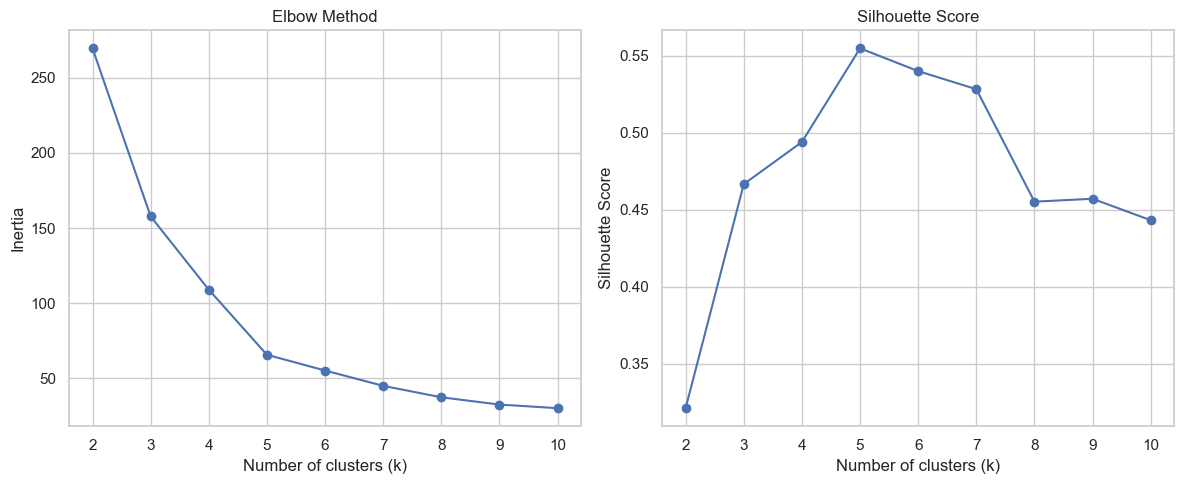

In [12]:
# TODO 8: Create two charts using metrics_df.
# Chart 1: k vs. inertia; chart 2: k vs. silhouette.
# Sắp xếp theo k để đường biểu đồ nối các điểm đúng thứ tự

# Tạo hai biểu đồ nằm cạnh nhau
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Biểu đồ 1: Elbow Curve
axes[0].plot(
    metrics_df["k"],
    metrics_df["inertia"],
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_xticks(metrics_df["k"])
axes[0].grid(True)

# Biểu đồ 2: Silhouette Score
axes[1].plot(
    metrics_df["k"],
    metrics_df["silhouette"],
    marker="o"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_xticks(metrics_df["k"])
axes[1].grid(True)

plt.tight_layout()
plt.show()

**Support your decision with reasoning:**

- The elbow appears near `k = ...` because ...
- The highest Silhouette Score occurs at `k = ...`, but ...
- I selected `k = ...` for my final model because ...
- One drawback of choosing a very large `k` is ...

## Part 6. Final model and cluster visualization (10 points)

**Task 6.1.** Set `k_final` to your selected number of clusters (**5** is shown only as an illustration; you may choose a different value).

**Task 6.2.** Fit K-means to the scaled data and add the cluster assignment for each customer to a DataFrame named `result`.

**Task 6.3.** Plot a cluster-colored scatter plot and mark the **centroids in the original units** using `scaler.inverse_transform()`.

In [53]:
# TODO 9: Replace 5 with your selected k and justify it in your report.
# Task 6.1: Set the final number of clusters
k_final = 5

# Task 6.2: Fit K-means on the scaled data and get a label for each customer
final_model = KMeans(
    n_clusters=k_final,
    random_state=42,
    n_init=10
)

final_labels = final_model.fit_predict(X_scaled)

# Copy the original data and add each customer's cluster label
result = df.copy()
result["Cluster"] = final_labels

display(result)
print("Number of customers in each cluster:")
print(result["Cluster"].value_counts().sort_index())

c:\Users\Ta Van Toan\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
...,...,...,...,...,...,...
195,196,Female,35,120,79,1
196,197,Female,45,126,28,3
197,198,Male,32,126,74,1
198,199,Male,32,137,18,3


Number of customers in each cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


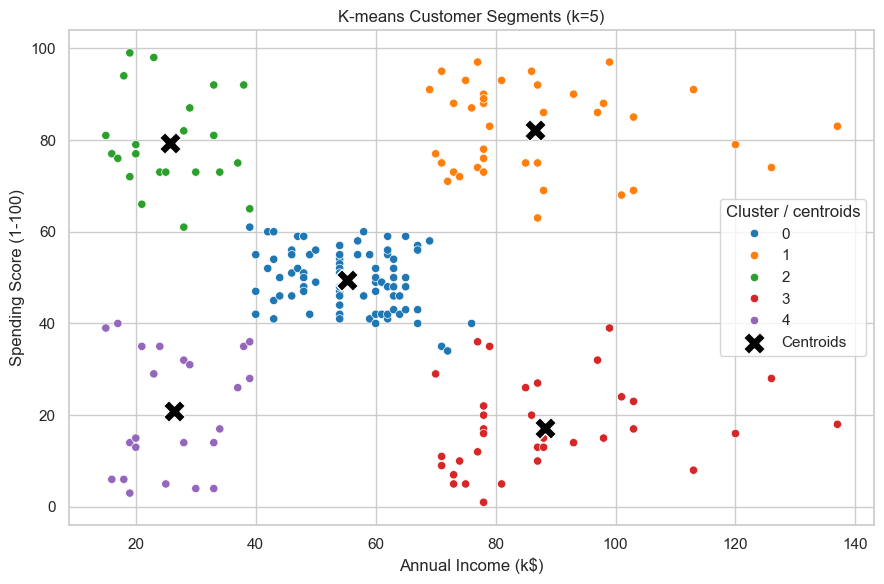

In [54]:
# TODO 10: Plot clusters by annual income and spending score.
# Centroid hint: scaler.inverse_transform(final_model.cluster_centers_)
# Convert centroid coordinates back to the original units
centroids_original = scaler.inverse_transform(final_model.cluster_centers_)

fig, ax = plt.subplots(figsize=(9, 6))

# Each color represents one cluster
sns.scatterplot(
    data=result,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue=result["Cluster"],
    palette="tab10",
    ax=ax
)

# Add centroids as large black X markers
ax.scatter(
    centroids_original[:, 0],
    centroids_original[:, 1],
    marker="X",
    s=250,
    color="black",
    edgecolor="white",
    linewidth=1,
    label="Centroids"
)

ax.set_title(f"K-means Customer Segments (k={k_final})")
ax.set_xlabel("Annual Income (k$)")
ax.set_ylabel("Spending Score (1-100)")

# Include both the cluster colors and centroid marker in the legend
handles, legend_labels = ax.get_legend_handles_labels()
ax.legend(handles, legend_labels, title="Cluster / centroids")

plt.tight_layout()
plt.show()

## Part 7. Customer segment profiling and naming (15 points)

**Task 7.1.** Calculate the customer count and percentage share of each cluster.

**Task 7.2.** Calculate mean age, mean annual income, mean spending score, and the gender composition of each cluster.

**Task 7.3.** Give **each cluster a descriptive name based on its actual statistics**, such as “high income – low spending score” or “medium income – high spending score.” **Do not assume that cluster 0 has a fixed meaning.**

In [55]:
# TODO 11: Create profile_df summarizing each Cluster.
# Count and percentage share of customers in each cluster.
profile_df = result.groupby("Cluster").agg(
    customer_count=("Cluster", "size"),
    mean_age=("Age", "mean"),
    mean_income_k=("Annual Income (k$)", "mean"),
    mean_spending_score=("Spending Score (1-100)", "mean")
)
profile_df["customer_share_percent"] = (
    profile_df["customer_count"] / len(result) * 100
).round(1)

# Show the percentage composition of gender within each cluster.
gender_share = pd.crosstab(
    result["Cluster"], result["Gender"], normalize="index"
).mul(100).round(1).add_prefix("gender_%_")
profile_df = profile_df.join(gender_share)

display(profile_df.round(2))

,customer_count,mean_age,mean_income_k,mean_spending_score,customer_share_percent,gender_%_Female,gender_%_Male
Cluster,,,,,,,
0,81,42.72,55.30,49.52,40.5,59.3,40.7
1,39,32.69,86.54,82.13,19.5,53.8,46.2
2,22,25.27,25.73,79.36,11.0,59.1,40.9
3,35,41.11,88.20,17.11,17.5,45.7,54.3
4,23,45.22,26.30,20.91,11.5,60.9,39.1


Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


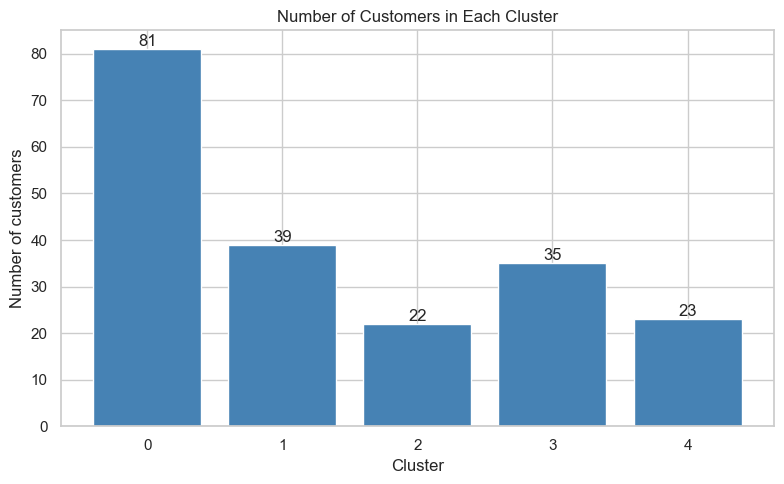

In [56]:
# TODO 12: Draw a bar chart of the number of customers per cluster.
cluster_counts = result["Cluster"].value_counts().sort_index()
print(cluster_counts)
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(cluster_counts.index.astype(str), cluster_counts.values, color="steelblue")
ax.set_title("Number of Customers in Each Cluster")
ax.set_xlabel("Cluster")
ax.set_ylabel("Number of customers")

for i, count in enumerate(cluster_counts.values):
    ax.text(i, count, str(count), ha="center", va="bottom")

plt.tight_layout()
plt.show()

**Interpretation table to complete** (replace `...` with your findings):

| Cluster | Your segment name | Key characteristics | Marketing strategy to test |
|---|---|---|---|
| 0 | ... | ... | ... |
| 1 | ... | ... | ... |
| ... | ... | ... | ... |

> Add or remove rows as needed if `k_final` is not 5.

**Possible marketing hypotheses:** a loyalty program for customers with high spending scores; trial offers for customers with low spending scores; targeted advertising messages; A/B tests before a large-scale rollout. These ideas are **business hypotheses**, not verified effects.

## Part 8. Sensitivity analysis and extensions (10 points)

**Task 8.1.** Run K-means with the same number of clusters but **without scaling**. Compare the two sets of assignments using `adjusted_rand_score()`.

**Task 8.2.** Add `Age` as a third clustering feature (with scaling) and compare the outcomes with the two-feature model.

**Interpreting ARI:** A value close to `1` indicates highly similar partitions; a value near `0` indicates agreement comparable to chance. ARI alone does not tell us which segmentation is more useful for marketing.

In [57]:
# TODO 13: Compare the scaled and unscaled K-means models.
# Fit K-means on the original, unscaled features
unscaled_model = KMeans(
    n_clusters=k_final,
    random_state=42,
    n_init=10
)
unscaled_labels = unscaled_model.fit_predict(X)

# Compare cluster assignments for the same customers
ari_unscaled = adjusted_rand_score(final_labels, unscaled_labels)

print("ARI (scaled vs. unscaled):", ari_unscaled)

ARI (scaled vs. unscaled): 1.0


c:\Users\Ta Van Toan\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [59]:
# TODO 14: Experiment with three features (Age, Income, Spending Score).
# Fit K-means on the original, unscaled features
# Select Age, Income, and Spending Score
features_3 = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]
X_3 = df[features_3]

# Use a separate scaler so the original Part 3 scaler remains unchanged
scaler_3 = StandardScaler()
X_3_scaled = scaler_3.fit_transform(X_3)

# Fit a three-feature K-means model using the same k
model_3 = KMeans(
    n_clusters=k_final,
    random_state=42,
    n_init=10
)
labels_3 = model_3.fit_predict(X_3_scaled)

# Compare the two-feature and three-feature assignments
ari_age_added = adjusted_rand_score(final_labels, labels_3)

print("ARI (two features vs. three features):", ari_age_added)
print(
    "Silhouette, two features:",
    silhouette_score(X_scaled, final_labels)
)
print(
    "Silhouette, three features:",
    silhouette_score(X_3_scaled, labels_3)
)

c:\Users\Ta Van Toan\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


ARI (two features vs. three features): 0.5844675873661414
Silhouette, two features: 0.5546571631111091
Silhouette, three features: 0.41664341513732767


**Discussion questions:** (a) How does adding `Age` change the clusters? (b) Should Silhouette Scores from two-dimensional and three-dimensional feature spaces be the sole basis for deciding which set of features is better? (c) Which feature set is more useful for a particular marketing decision?

**Your answer:** ...

## Part 9. Application: assign a new customer and export the results

**Task 9.1.** Consider a hypothetical customer with an annual income of **70 thousand USD** and a spending score of **80**. Use the **previously fitted scaler** (`scaler.transform`, not `fit_transform`) to assign this customer to a cluster.

**Task 9.2.** Save customer-level assignments to `customer_segments.csv` and the cluster summary to `cluster_profiles.csv`.

**Important:** A cluster label only shows which centroid is closest; it is not a purchase probability.

In [60]:
# TODO 15: Assign the hypothetical customer to a cluster.
# Keep the feature names and order the same as in Part 3.
new_customer = pd.DataFrame(
    [[70, 80]],
    columns=features
)

# Use transform (not fit_transform) so the new customer uses the
# same scaling learned from the training data.
new_scaled = scaler.transform(new_customer)
new_cluster = final_model.predict(new_scaled)[0]

print("New customer:")
display(new_customer)
print("Assigned cluster:", new_cluster)

New customer:


,Annual Income (k$),Spending Score (1-100)
0,70,80


Assigned cluster: 1


In [61]:
# TODO 16: Export customer-level assignments and cluster profiles.
result.to_csv("customer_segments.csv", index=False)
profile_df.to_csv("cluster_profiles.csv", index_label="Cluster")

print("Saved customer_segments.csv and cluster_profiles.csv")

Saved customer_segments.csv and cluster_profiles.csv


## Part 10. Results report and business recommendations

Prepare a **1–2-page report** (written below or submitted as a separate PDF) addressing:

1. **Business problem:** Why is customer segmentation useful, and which management decision does this analysis support?
2. **Data and methods:** Which features were used? Why were they scaled? How was `k` selected?
3. **Results:** State the number and size of clusters; include at least one cluster plot and a cluster-profile table.
4. **Recommendations:** Propose **at least three specific marketing actions**, each linked to one or more identified segments.
5. **Limitations:** The dataset includes only 200 customers; a spending score is not revenue. There are no time-series records, transaction histories, campaign costs, or response labels, so **ROI and causal campaign effects cannot be inferred**.
6. **Next steps:** What additional data are needed to deploy the segmentation? How would you test whether a campaign is effective?

### Suggested report structure

**1. Objective:** ...

**2. Data and preprocessing:** ...

**3. Selecting the number of clusters:** ...

**4. Cluster descriptions and names:** ...

**5. Marketing recommendations and validation approach:** ...

**6. Limitations and additional data requirements:** ...

## Suggested grading rubric (100 points)

| Component | Points |
|---|---:|
| Data quality checks and handling decisions | 15 |
| Exploratory analysis and interpretation | 15 |
| Feature selection, scaling, and justification | 10 |
| K-means modeling and explanation | 10 |
| Elbow and Silhouette analysis, with justified `k` | 15 |
| Result visualization | 10 |
| Cluster interpretation and business recommendations | 15 |
| Sensitivity analysis / evaluation of limitations | 10 |
| **Total** | **100** |

**Submission:** A completed and executed `.ipynb` notebook, `customer_segments.csv`, `cluster_profiles.csv`, and a short report. Cite the Kaggle dataset and document your choice of `k`.

**Optional extension:** Run K-means with 10 different `random_state` values (keeping `n_init` constant), compare Inertia and ARI, and discuss clustering stability.